# Reconciling a flotation balance without inventing certainty

**Question:** How should we reconcile the feed, concentrate and tailings observations of one flotation parcel,
and what changes when we trust the feed meter less?

Level 1 · Prerequisites: Python arrays and the meaning of tonnes per hour. · Reading time: 25 minutes.

## Objectives

A flotation bank splits dry solids into concentrate and tailings. Three meters seldom close this balance
exactly, even when they are functioning normally. We will extract a small slice of the actual OreBridge
replay, calculate its disagreement, and ask the implemented weighted solver to distribute the correction.
The lesson ends by changing one uncertainty, so the allocation of that correction becomes an explicit
modeling choice rather than a hidden property of a dashboard. We will keep observed values and estimates
side by side: reconciliation adds an inference; it does not rewrite the instrument history.

## Setup

Work in a checkout of OreBridge with the notebook environment active. The computational methods live in
`data-pipeline/pipeline`, so the checkout is required; no released OreBridge PyPI distribution is implied.
Install the exact numerical dependencies once, outside this notebook:

```bash
pip install numpy==2.2.6 scipy==1.18.1 scikit-learn==1.9.1 matplotlib==3.11.2
```

Start the kernel with `OMP_NUM_THREADS=1`, `OPENBLAS_NUM_THREADS=1` and `MKL_NUM_THREADS=1`.
The setup finds the checkout from the working directory without printing a machine path.

In [1]:
# Use the pinned CPU environment and import the implemented scientific methods.
import json
import sys
import importlib.metadata
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "VERSION").is_file() and (p / "data-pipeline" / "pipeline").is_dir()
)
sys.path.insert(0, str(root / "data-pipeline"))
get_ipython().run_line_magic("matplotlib", "inline")
from pipeline.model.scenarios import align, conservation_matrix
from pipeline.model.reconciliation import weighted_reconcile
trace = json.loads((root / "data/derived/PL-01/trace.json").read_text(encoding="utf-8"))
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
for distribution in ["numpy", "scipy", "scikit-learn", "matplotlib"]:
    print(f"{distribution}: {importlib.metadata.version(distribution)}")

numpy: 2.2.6
scipy: 1.18.1
scikit-learn: 1.9.1
matplotlib: 3.11.2


## Data

Owner: the OreBridge project, [public repository](https://github.com/fsantibanezleal/CAOS_OreBridge).
File: `data/derived/PL-01/trace.json`, an authored synthetic known-truth replay distributed with the MIT
repository. Its channels are dry-solids rates in t/h. The clean signals and injected disturbances were
constructed for reproducible numerical experiments; they are not measurements from a mine. We use the
committed observations and channel uncertainties, not the trace's already computed estimates or alarms.

## Method

For one material parcel, conservation says $f-c-t=0$. The vector $y=(f,c,t)$ contains the three measured
rates, while $x$ denotes an estimate consistent with that equation. A meter's standard uncertainty $\sigma_j$
sets the cost of moving its reading. Constrained weighted least squares minimizes
$\sum_j[(x_j-y_j)/\sigma_j]^2$ subject to $Ax=0$, with $A=(1,-1,-1)$.
Mineral-processing reconciliation provides the context for this constrained formulation
([Sadeghi, Hodouin and Bazin](https://doi.org/10.1016/j.mineng.2018.04.023)). Our small calculation uses
only dry-solids conservation; it does not reproduce that paper's additional mineralogical constraints.

First select the actual flotation row from the network's conservation matrix. The imported alignment
operator groups observations by parcel using their declared delays. Its first fourteen seconds are
unavailable. Index 50 is safely beyond that boundary; the next lesson examines why this alignment matters.
A negative residual means that the two measured outputs sum to more than the measured input.

In [2]:
# Select matching dry-solids channels before forming a physical balance.
columns = [5, 6, 7]
constraint = conservation_matrix()[4:5, columns]
observed = align(trace["observed"])[50, columns]
sigma = np.array([trace["channels"][j]["sigma"] for j in columns])
names = [trace["channels"][j]["label"]["en"] for j in columns]
imbalance = float((constraint @ observed)[0])
print(f"Observed feed minus products: {imbalance:.6f} t/h")
print("Standard uncertainties in t/h:", np.round(sigma, 6))

Observed feed minus products: -3.275253 t/h
Standard uncertainties in t/h: [7.2      0.185991 7.014009]


The concentrate meter has a much smaller absolute uncertainty because its nominal dry-solids rate is
small. Equal relative precision does not mean equal absolute movement. Run the package solver with these
original uncertainties and retain both columns of the result. The normalized adjustments are useful for
comparing meters with different scales, but they are residual scores, not probabilities that a meter failed.

In [3]:
# Conserve the parcel and expose the observation-to-estimate adjustment.
reconciled = weighted_reconcile(observed, sigma, constraint, [0.0])
for name, measured, estimated, score in zip(names, observed, reconciled["state"], reconciled["score"]):
    print(f"{name}: observed={measured:.6f}, estimated={estimated:.6f} t/h; score={score:.4f}")
print("Reconciled balance residual:", np.round(reconciled["balance_residual"], 12), "t/h")

Flotation dry solids: observed=745.013031, estimated=746.692931 t/h; score=0.2333
Concentrate dry solids: observed=19.382758, estimated=19.381637 t/h; score=0.0060
Tailings dry solids: observed=728.905525, estimated=727.311294 t/h; score=0.2273
Reconciled balance residual: [-0.] t/h


Now triple only the feed meter's standard uncertainty. This multiplies its variance by nine, which makes
the same physical movement cheaper in the objective. The observation vector and conservation equation do
not change. This is a sensitivity calculation, not a claim that the feed meter was actually worse: in a
deployment, uncertainty needs calibration evidence and cannot be chosen to make a preferred meter look good.

In [4]:
# Change one confidence assumption while preserving the measured parcel.
less_trusted_sigma = sigma.copy()
less_trusted_sigma[0] *= 3
less_trusted = weighted_reconcile(observed, less_trusted_sigma, constraint, [0.0])
adjustments = np.column_stack([reconciled["state"] - observed, less_trusted["state"] - observed])
print(f"Feed adjustment: {adjustments[0, 0]:.6f} -> {adjustments[0, 1]:.6f} t/h")
print(f"Concentrate estimate with less trusted feed: {less_trusted['state'][1]:.6f} t/h")

Feed adjustment: 1.679901 -> 2.962638 t/h
Concentrate estimate with less trusted feed: 19.382538 t/h


The following figure separates the scale of the physical flows from the scale of their corrections.
Compare the two correction bars for each meter: their sign follows the conservation equation, while their
relative sizes follow the uncertainty model. Keep in mind that a visually tiny concentrate adjustment can
still be meaningful relative to its much smaller standard uncertainty.

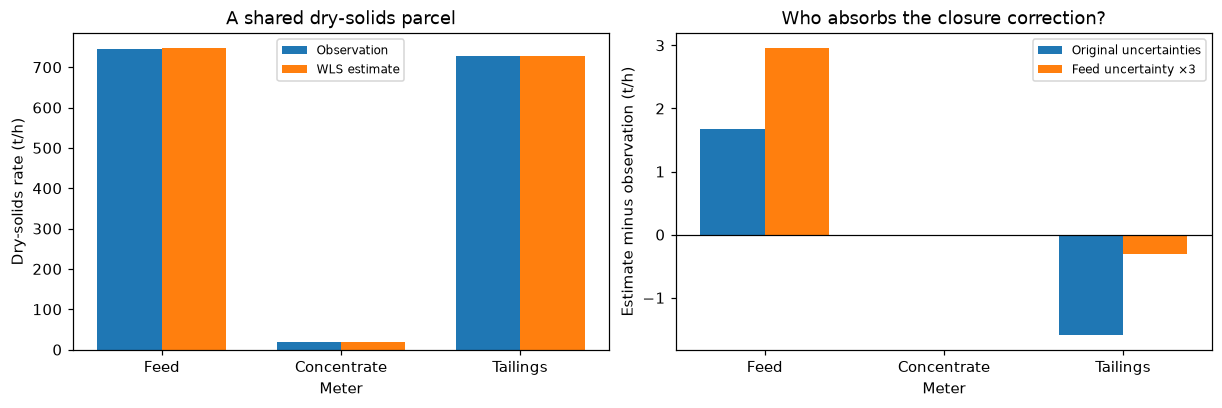

In [5]:
# Plot absolute rates separately from uncertainty-dependent adjustments.
positions = np.arange(3)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
axes[0].bar(positions - 0.18, observed, 0.36, label="Observation")
axes[0].bar(positions + 0.18, reconciled["state"], 0.36, label="WLS estimate")
axes[0].set(title="A shared dry-solids parcel", ylabel="Dry-solids rate (t/h)")
axes[1].bar(positions - 0.18, adjustments[:, 0], 0.36, label="Original uncertainties")
axes[1].bar(positions + 0.18, adjustments[:, 1], 0.36, label="Feed uncertainty ×3")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(title="Who absorbs the closure correction?", ylabel="Estimate minus observation (t/h)")
for axis in axes:
    axis.set_xticks(positions, ["Feed", "Concentrate", "Tailings"])
    axis.set_xlabel("Meter")
    axis.legend(fontsize=8)
plt.show()

The large bars on the left explain why a few tonnes per hour of disagreement can be hard to see in a plant
overview. The right panel reveals the allocation: lower feed confidence shifts more of the required
correction onto feed. Neither panel establishes which reading was wrong. One equation constrains three
unknown flows, so the solver's unique weighted optimum depends on assumptions that the measurements alone
cannot verify. A closed balance is therefore a consistency result, not an instrument certificate.

As a final limiting case, reconcile the nominal rates from the same channel manifest. They already close,
so a sound projection should leave them unchanged. This makes the distinction between enforcing an equation
and forcing an arbitrary new operating point concrete.

In [6]:
# Check the physically meaningful limit of an already balanced observation.
nominal = np.array([trace["channels"][j]["nominal"] for j in columns])
already_closed = weighted_reconcile(nominal, sigma, constraint, [0.0])
print(f"Largest nominal adjustment: {np.max(np.abs(already_closed['state'] - nominal)):.12f} t/h")
print(f"Constraint rank: {already_closed['rank']}; unconstrained directions: {len(columns) - already_closed['rank']}")

Largest nominal adjustment: 0.000000000000 t/h
Constraint rank: 1; unconstrained directions: 2


## Results

**Answer:** The selected parcel has a measured feed-minus-products residual of -3.275253 t/h. With the
original uncertainties, WLS estimates feed at 746.692931 t/h, concentrate at 19.381637 t/h and tailings at
727.311294 t/h. Tripling feed uncertainty raises its adjustment from 1.679901 to 2.962638 t/h. The nominal
closed parcel needs a 0.000000000000 t/h adjustment. These numbers answer how the correction is allocated;
they do not identify a faulty instrument.

A practitioner can reuse this calculation by replacing the three observations, their calibrated standard
uncertainties and the appropriate material-balance row. Do not mix slurry volume with dry-solids mass, or
use a common timestamp as proof that two meters saw the same parcel. Negative rates are not explicitly
prohibited by this linear solver; an admissible operating envelope needs an additional validation decision.

## Summary

Conservation supplied a feasible surface; uncertainty selected a point on it. Observations remained
visible throughout. Before interpreting a correction as evidence of a process problem, the next lesson
checks two ways a healthy plant can violate an instantaneous equation: travel time and changing inventory.

## References

- Sadeghi, Hodouin and Bazin (2018), *Mineral processing plant data reconciliation including mineral mass
  balance constraints*. https://doi.org/10.1016/j.mineng.2018.04.023
- Implementation: `pipeline.model.reconciliation.weighted_reconcile`; channel and transport definitions:
  `data-pipeline/pipeline/model/scenarios.py`; replay: `data/derived/PL-01/trace.json`.